## ANN Model Building

### Importing libraries

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import joblib
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


### Loading the prepared data

In [7]:
X_train = np.load("../data/processed/X_train.npy")
X_test = np.load("../data/processed/X_test.npy")

y_train = np.load("../data/processed/y_train.npy")
y_test = np.load("../data/processed/y_test.npy")

label_encoder = joblib.load("../models/label_encoder.pkl")

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Number of disease classes:",
      len(label_encoder.classes_))

Training data: (243, 131)
Testing data: (61, 131)
Number of disease classes: 41


### Creating validation data

In [8]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Final training data:", X_train_final.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Final training data: (194, 131)
Validation data: (49, 131)
Testing data: (61, 131)


### Defining the ANN architecture

In [9]:
input_features = X_train_final.shape[1]
number_of_classes = len(label_encoder.classes_)

model = Sequential([
    Input(shape=(input_features,)),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(number_of_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 41)                  │           2,665 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 27,817 (108.66 KB)

 Trainable params: 27,817 (108.66 KB)

 Non-trainable params: 0 (0.00 B)

### Compiling the ANN model

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("ANN model compiled successfully!")

ANN model compiled successfully!


### Configuring callbacks

In [11]:
os.makedirs("../models", exist_ok=True)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

checkpoint = ModelCheckpoint(
    "../models/best_ann_model.keras",
    monitor="val_loss",
    save_best_only=True
)

print("Callbacks configured successfully!")

Callbacks configured successfully!


### Training the ANN model

In [12]:
history = model.fit(
    X_train_final,
    y_train_final,

    validation_data=(X_val, y_val),

    epochs=100,
    batch_size=16,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 257ms/step - accuracy: 0.0361 - loss: 3.8327 - val_accuracy: 0.1429 - val_loss: 3.2540 - learning_rate: 0.0010
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.1701 - loss: 3.2121 - val_accuracy: 0.4694 - val_loss: 2.7250 - learning_rate: 0.0010
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.4330 - loss: 2.6598 - val_accuracy: 0.8163 - val_loss: 2.2409 - learning_rate: 0.0010
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.5412 - loss: 2.3170 - val_accuracy: 0.8980 - val_loss: 1.7720 - learning_rate: 0.0010
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6907 - loss: 1.8514 - val_accuracy: 0.9184 - val_loss: 1.3508 - learning_rate: 0.0010
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.7732 - loss: 1.4520 - val_accuracy: 0.9388 - val_loss: 1.0079 - learning_rate: 0.0010
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8608 - loss: 1.1083 

### Plot training and validation accuracy

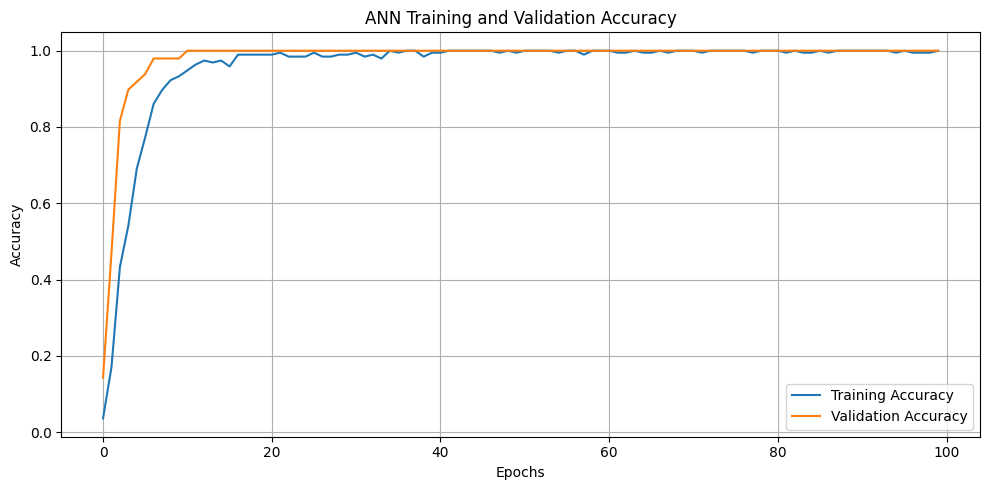

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Plot training and validation loss

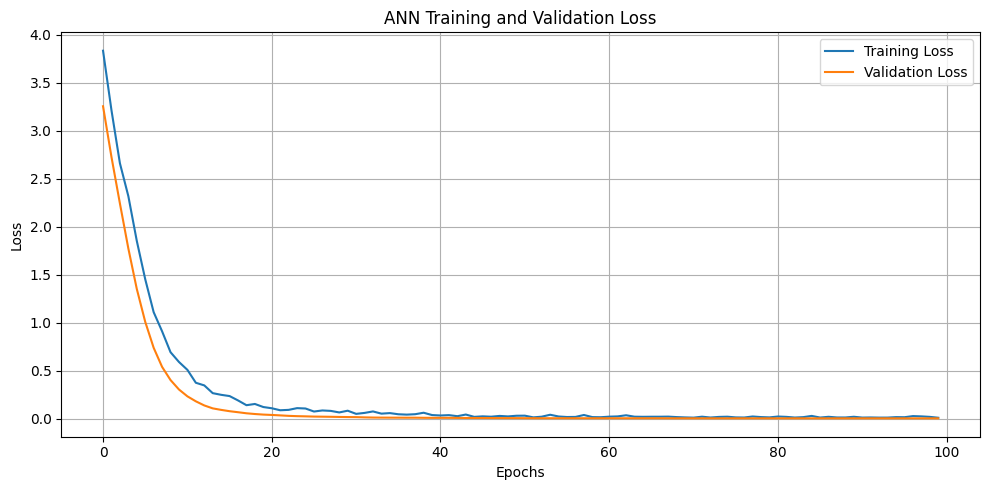

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Saving the final model

In [15]:
model.save("../models/disease_ann_model.keras")

print("ANN model saved successfully!")

ANN model saved successfully!
